# Customer Churn Prediction Using K-Nearest Neighbors (KNN)

## Project Overview

This project aims to predict customer churn using the Telco Customer Churn dataset. The goal is to identify customers who are likely to leave the service based on their demographic information, account details, and subscribed services.

The project includes exploratory data analysis, data preprocessing, feature encoding and scaling, model training, and hyperparameter tuning using `GridSearchCV`.

Finally, the selected model is evaluated using classification metrics, and the best-performing configuration is used to train the final model.


In [1]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
from sklearn.preprocessing import LabelEncoder,OneHotEncoder,OrdinalEncoder,StandardScaler
from sklearn.pipeline import Pipeline
import warnings 
from sklearn.neighbors import KNeighborsClassifier
from sklearn.compose import ColumnTransformer
from sklearn.model_selection import train_test_split,GridSearchCV,ShuffleSplit
import seaborn as sns
from sklearn.impute import KNNImputer
from sklearn.metrics import classification_report

In [2]:
warnings.filterwarnings('ignore')

## Loading and Inspecting the Dataset

First, we load the Telco Customer Churn dataset into a Pandas DataFrame. We then inspect the first few rows to understand the structure of the data, its features, and the information available for analysis.


In [3]:
data=pd.read_csv("WA_Fn-UseC_-Telco-Customer-Churn.csv")

In [4]:
data.head()

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [5]:
data.columns

Index(['customerID', 'gender', 'SeniorCitizen', 'Partner', 'Dependents',
       'tenure', 'PhoneService', 'MultipleLines', 'InternetService',
       'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport',
       'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling',
       'PaymentMethod', 'MonthlyCharges', 'TotalCharges', 'Churn'],
      dtype='object')

In [6]:
data.dtypes

customerID           object
gender               object
SeniorCitizen         int64
Partner              object
Dependents           object
tenure                int64
PhoneService         object
MultipleLines        object
InternetService      object
OnlineSecurity       object
OnlineBackup         object
DeviceProtection     object
TechSupport          object
StreamingTV          object
StreamingMovies      object
Contract             object
PaperlessBilling     object
PaymentMethod        object
MonthlyCharges      float64
TotalCharges         object
Churn                object
dtype: object

In [7]:
data.isna().sum()

customerID          0
gender              0
SeniorCitizen       0
Partner             0
Dependents          0
tenure              0
PhoneService        0
MultipleLines       0
InternetService     0
OnlineSecurity      0
OnlineBackup        0
DeviceProtection    0
TechSupport         0
StreamingTV         0
StreamingMovies     0
Contract            0
PaperlessBilling    0
PaymentMethod       0
MonthlyCharges      0
TotalCharges        0
Churn               0
dtype: int64

## Exploratory Data Analysis

In this section, we explore the dataset using visualizations to better understand customer churn. The charts examine the relationship between churn and features such as contract type, tenure, senior citizen status, and monthly charges.


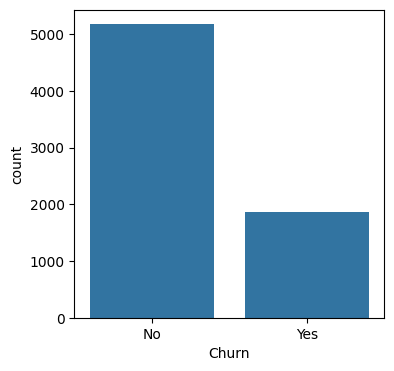

In [8]:
plt.figure(figsize=(4,4))
sns.countplot(data,x=data["Churn"])
plt.show()

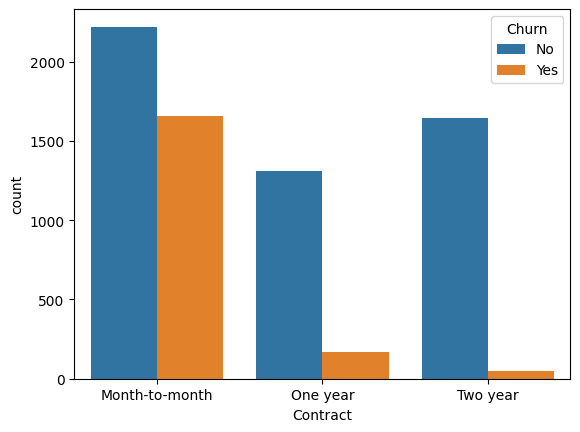

In [9]:
sns.countplot(data,x=data.Contract,hue=data["Churn"])
plt.show()

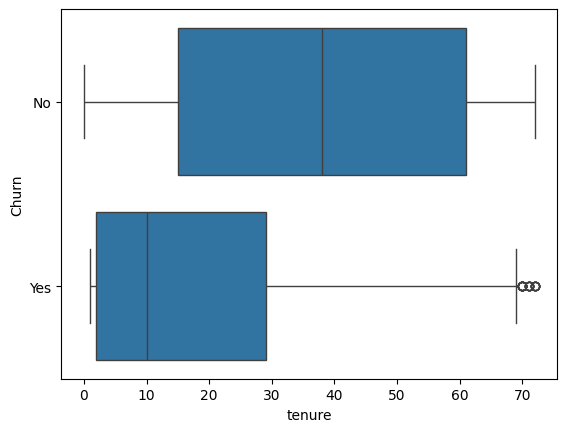

In [10]:
sns.boxplot(data,x=data.tenure,y=data["Churn"])
plt.show()

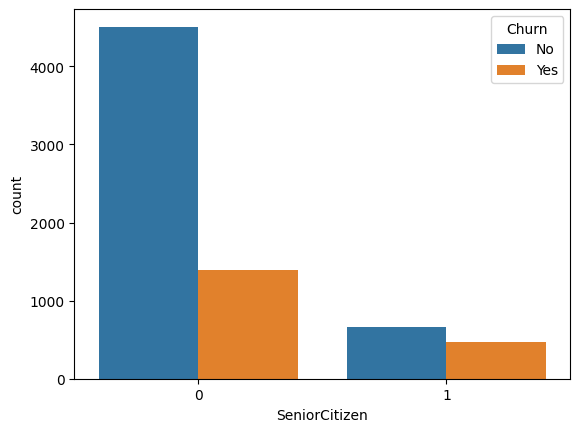

In [11]:
sns.countplot(data,x=data.SeniorCitizen,hue=data.Churn)
plt.show()

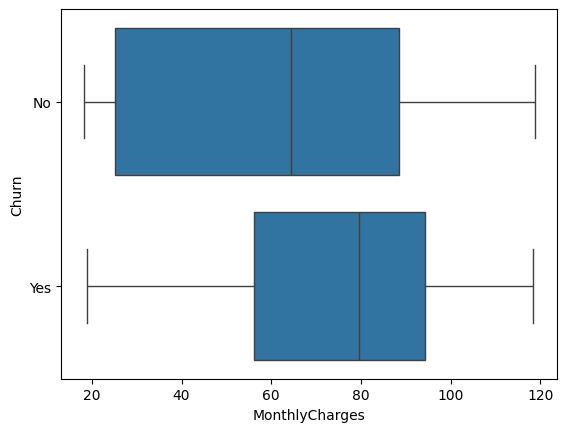

In [12]:
sns.boxplot(data,x=data.MonthlyCharges,y=data.Churn)
plt.show()

## Handling Missing Values

During the initial data inspection, blank entries were identified in the `TotalCharges` column. In this step, these blank entries are replaced with `NaN` values so they can be handled appropriately during data preprocessing.

In [13]:
data['TotalCharges'].replace(' ',np.nan,inplace=True)
data['TotalCharges'].isna().sum()

11

In [14]:
data["TotalCharges"] = pd.to_numeric(
    data["TotalCharges"], errors="coerce")

data_numeric = data.select_dtypes(["int64", "float64"])
data_categorical = data.select_dtypes("object").drop(columns="customerID")

data_bin = data_categorical[['gender', 'Partner', 'Dependents','PhoneService', 'PaperlessBilling']]

data_target = data_categorical['Churn']

data_cat = data_categorical.drop(columns=['gender', 'Partner', 'Dependents', 'PhoneService','PaperlessBilling', 'Churn'])

In [15]:
#binarize_columns
data_cat.nunique()

MultipleLines       3
InternetService     3
OnlineSecurity      3
OnlineBackup        3
DeviceProtection    3
TechSupport         3
StreamingTV         3
StreamingMovies     3
Contract            3
PaymentMethod       4
dtype: int64

### Encoding Categorical Features

Machine learning algorithms require numerical input, so categorical features must be converted into numerical representations.

In this project, `OneHotEncoder` and `OrdinalEncoder` are applied to categorical features using `ColumnTransformer`, while `LabelEncoder` is used to encode the target variable, `Churn`. These transformations are integrated into the preprocessing workflow.


In [16]:
X = data.drop(columns=["Churn", "customerID"])
y = LabelEncoder().fit_transform(data["Churn"])

In [17]:
X_train, X_test, y_train, y_test = train_test_split(X,y,test_size=0.3,random_state=1234,stratify=y)


In [18]:
numeric_pipeline = Pipeline([
    ("imputer", KNNImputer()),
    ("scaler", StandardScaler())])

In [19]:
preprocessor = ColumnTransformer([
    ("num", numeric_pipeline, data_numeric.columns.tolist()),
    ("ohe", OneHotEncoder(handle_unknown="ignore"), data_cat.columns.tolist()),
    ("bin", OrdinalEncoder(), data_bin.columns.tolist())])

## Building the KNN Pipeline

We combine the preprocessing steps and the K-Nearest Neighbors (KNN) classifier into a single pipeline. This ensures that imputation, scaling, and categorical encoding are applied consistently during training and prediction.

In [20]:
pipe = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("model", KNeighborsClassifier(n_neighbors=13, p=2))])

In [21]:
pipe.fit(X_train,y_train)

Pipeline(steps=[('preprocessor',
                 ColumnTransformer(transformers=[('num',
                                                  Pipeline(steps=[('imputer',
                                                                   KNNImputer()),
                                                                  ('scaler',
                                                                   StandardScaler())]),
                                                  ['SeniorCitizen', 'tenure',
                                                   'MonthlyCharges',
                                                   'TotalCharges']),
                                                 ('ohe',
                                                  OneHotEncoder(handle_unknown='ignore'),
                                                  ['MultipleLines',
                                                   'InternetService',
                                                   'OnlineSecurity',
                                                   'OnlineBackup',
                                                   'DeviceProtection',
                                                   'TechSupport', 'StreamingTV',
                                                   'StreamingMovies',
                                                   'Contract',
                                                   'PaymentMethod']),
                                                 ('bin', OrdinalEncoder(),
                                                  ['gender', 'Partner',
                                                   'Dependents', 'PhoneService',
                                                   'PaperlessBilling'])])),
                ('model', KNeighborsClassifier(n_neighbors=13))])

In [ ]:
y_pred = pipe.predict(X_test)
print(classification_report(y_test, y_pred))

In [23]:
print(pipe.score(X_train,y_train))
print(pipe.score(X_test,y_test))

0.8186612576064909
0.7657359204921912


## Hyperparameter Tuning

We used `GridSearchCV` to experiment with different values of `n_neighbors` and `p` in the K-Nearest Neighbors (KNN) classifier. After comparing the candidate combinations using cross-validation, the best-performing configuration was selected based on the cross-validation score.

The selected hyperparameters were `n_neighbors=29` and `p=1`.


In [24]:
params={'model__n_neighbors':[29,13],'model__p':[1,3],'model__weights':['uniform']}
cv=ShuffleSplit(n_splits=4,random_state=123,test_size=.3)

In [25]:
cls=GridSearchCV(
    pipe,
    param_grid=params,
    cv=cv,
    verbose=1,
    return_train_score=True,
    scoring='accuracy',
    error_score='raise')
cls.fit(X_train,y_train)

Fitting 4 folds for each of 4 candidates, totalling 16 fits


GridSearchCV(cv=ShuffleSplit(n_splits=4, random_state=123, test_size=0.3, train_size=None),
             error_score='raise',
             estimator=Pipeline(steps=[('preprocessor',
                                        ColumnTransformer(transformers=[('num',
                                                                         Pipeline(steps=[('imputer',
                                                                                          KNNImputer()),
                                                                                         ('scaler',
                                                                                          StandardScaler())]),
                                                                         ['SeniorCitizen',
                                                                          'tenure',
                                                                          'MonthlyCharges',
                                                                          'TotalCharges']),
                                                                        ('ohe',
                                                                         OneHotEncoder(handle_un...
                                                                          'TechSupport',
                                                                          'StreamingTV',
                                                                          'StreamingMovies',
                                                                          'Contract',
                                                                          'PaymentMethod']),
                                                                        ('bin',
                                                                         OrdinalEncoder(),
                                                                         ['gender',
                                                                          'Partner',
                                                                          'Dependents',
                                                                          'PhoneService',
                                                                          'PaperlessBilling'])])),
                                       ('model',
                                        KNeighborsClassifier(n_neighbors=13))]),
             param_grid={'model__n_neighbors': [29, 13], 'model__p': [1, 3],
                         'model__weights': ['uniform']},
             return_train_score=True, scoring='accuracy', verbose=1)

## Model Evaluation

The best model is evaluated on the test set using the optimal hyperparameters selected by `GridSearchCV`. The classification report provides precision, recall, F1-score, and support for each class.

In [26]:
cls.best_score_
y_pred_test=cls.predict(X_test)
print(classification_report(y_test,y_pred_test))

              precision    recall  f1-score   support

           0       0.84      0.86      0.85      1552
           1       0.58      0.56      0.57       561

    accuracy                           0.78      2113
   macro avg       0.71      0.71      0.71      2113
weighted avg       0.78      0.78      0.78      2113



In [27]:
print(classification_report(y_train,cls.predict(X_train)))

              precision    recall  f1-score   support

           0       0.86      0.88      0.87      3622
           1       0.64      0.61      0.63      1308

    accuracy                           0.81      4930
   macro avg       0.75      0.75      0.75      4930
weighted avg       0.80      0.81      0.81      4930



### Visualizing Hyperparameter Tuning Results

The training and cross-validation scores are visualized to compare model performance across different hyperparameter combinations and identify potential overfitting.


In [28]:
m_train_score=cls.cv_results_["mean_train_score"]
m_test_score=cls.cv_results_["mean_test_score"]
test_max=m_test_score.max()
train_max=m_train_score.max()
arg=m_test_score.argmax()
cls.cv_results_["params"][arg]

{'model__n_neighbors': 29, 'model__p': 1, 'model__weights': 'uniform'}

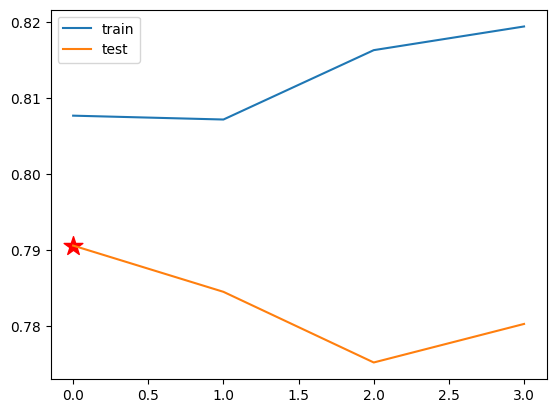

In [29]:
plt.plot(range(len(m_train_score)),m_train_score,label='train')
plt.plot(range(len(m_train_score)),m_test_score,label='test')
plt.scatter(arg,test_max,color='red',marker='*',s=200)
plt.legend()
plt.show()

### Training the Final Model

After selecting the best hyperparameters using `GridSearchCV`, we create a copy of the best estimator and train it on the full dataset. This allows the final model to learn from all available data.


In [30]:
from sklearn.base import clone
# Train the final model on the full dataset
final_model = clone(cls.best_estimator_)
final_model.fit(X,y)

Pipeline(steps=[('preprocessor',
                 ColumnTransformer(transformers=[('num',
                                                  Pipeline(steps=[('imputer',
                                                                   KNNImputer()),
                                                                  ('scaler',
                                                                   StandardScaler())]),
                                                  ['SeniorCitizen', 'tenure',
                                                   'MonthlyCharges',
                                                   'TotalCharges']),
                                                 ('ohe',
                                                  OneHotEncoder(handle_unknown='ignore'),
                                                  ['MultipleLines',
                                                   'InternetService',
                                                   'OnlineSecurity',
                                                   'OnlineBackup',
                                                   'DeviceProtection',
                                                   'TechSupport', 'StreamingTV',
                                                   'StreamingMovies',
                                                   'Contract',
                                                   'PaymentMethod']),
                                                 ('bin', OrdinalEncoder(),
                                                  ['gender', 'Partner',
                                                   'Dependents', 'PhoneService',
                                                   'PaperlessBilling'])])),
                ('model', KNeighborsClassifier(n_neighbors=29, p=1))])

### Saving the Final Model

The final trained model is saved as a `.pkl` file using Python's `pickle` module. This allows the model to be loaded and reused later without retraining.

In [31]:
# Save the final model
import pickle
with open("final_knn_churn_model.pkl", "wb") as file:
    pickle.dump(final_model, file)